## Load libraries

In [1]:
import polars as pl
import os
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import polars as pl
pl.Config.set_tbl_rows(20)  # show up to 20 rows
import polars.selectors as cs
import seaborn as sns
sns.set_style("darkgrid")  # darkgrid
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import numpy as np
import pandas as pd

In [2]:
def csv_to_parquet(path):
    os.makedirs("data", exist_ok=True)

    filename = os.path.basename(path)
    parquet_filename = filename.replace(".csv", ".parquet")
    parquet_path = os.path.join("data", parquet_filename)

    # lazy scan (does NOT load everything into RAM)
    lf = pl.scan_csv(
        path,
        infer_schema_length=1000,
        ignore_errors=True
    )

    # stream directly to parquet
    lf.sink_parquet(
        parquet_path,
        compression="snappy"
    )

    print(f"Saved Parquet file to: {parquet_path}")

### Convert pandas to polar

In [3]:
has_parquet = any(f.endswith(".parquet") for f in os.listdir("data"))

if has_parquet:
    print("Parquet file already exists in data folder")
else:
    print("No parquet file found. Converting CSV → Parquet...")
    csv_to_parquet("data/accepted_2007_to_2018Q4.csv")

Parquet file already exists in data folder


### Read accepted_df

In [4]:
# Never use CSV again
accepted_df = pl.read_parquet("accepted_2007_to_2018Q4.parquet")
accepted_df.head()

id,member_id,loan_amnt,funded_amnt,funded_amnt_inv,term,int_rate,installment,grade,sub_grade,emp_title,emp_length,home_ownership,annual_inc,verification_status,issue_d,loan_status,pymnt_plan,url,desc,purpose,title,zip_code,addr_state,dti,delinq_2yrs,earliest_cr_line,fico_range_low,fico_range_high,inq_last_6mths,mths_since_last_delinq,mths_since_last_record,open_acc,pub_rec,revol_bal,revol_util,total_acc,…,total_il_high_credit_limit,revol_bal_joint,sec_app_fico_range_low,sec_app_fico_range_high,sec_app_earliest_cr_line,sec_app_inq_last_6mths,sec_app_mort_acc,sec_app_open_acc,sec_app_revol_util,sec_app_open_act_il,sec_app_num_rev_accts,sec_app_chargeoff_within_12_mths,sec_app_collections_12_mths_ex_med,sec_app_mths_since_last_major_derog,hardship_flag,hardship_type,hardship_reason,hardship_status,deferral_term,hardship_amount,hardship_start_date,hardship_end_date,payment_plan_start_date,hardship_length,hardship_dpd,hardship_loan_status,orig_projected_additional_accrued_interest,hardship_payoff_balance_amount,hardship_last_payment_amount,disbursement_method,debt_settlement_flag,debt_settlement_flag_date,settlement_status,settlement_date,settlement_amount,settlement_percentage,settlement_term
i64,str,f64,f64,f64,str,f64,f64,str,str,str,str,str,f64,str,str,str,str,str,str,str,str,str,str,f64,f64,str,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,str,f64,f64,str,str,str,f64,f64,str,f64,f64,f64,str,str,str,str,str,f64,f64,f64
68407277,null,3600.0,3600.0,3600.0,""" 36 months""",13.99,123.03,"""C""","""C4""","""leadman""","""10+ years""","""MORTGAGE""",55000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""debt_consolidation""","""Debt consolidation""","""190xx""","""PA""",5.91,0.0,"""Aug-2003""",675.0,679.0,1.0,30.0,null,7.0,0.0,2765.0,29.7,13.0,…,13734.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68355089,null,24700.0,24700.0,24700.0,""" 36 months""",11.99,820.28,"""C""","""C1""","""Engineer""","""10+ years""","""MORTGAGE""",65000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""small_business""","""Business""","""577xx""","""SD""",16.06,1.0,"""Dec-1999""",715.0,719.0,4.0,6.0,null,22.0,0.0,21470.0,19.2,38.0,…,24667.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68341763,null,20000.0,20000.0,20000.0,""" 60 months""",10.78,432.66,"""B""","""B4""","""truck driver""","""10+ years""","""MORTGAGE""",63000.0,"""Not Verified""","""Dec-2015""","""Fully Paid""","""n""","""https://lendingclub.com/browse…",null,"""home_improvement""",null,"""605xx""","""IL""",10.78,0.0,"""Aug-2000""",695.0,699.0,0.0,null,null,6.0,0.0,7869.0,56.2,18.0,…,14877.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
66310712,null,35000.0,35000.0,35000.0,""" 60 months""",14.85,829.9,"""C""","""C5""","""Information Systems Officer""","""10+ years""","""MORTGAGE""",110000.0,"""Source Verified""","""Dec-2015""","""Current""","""n""","""https://lendingclub.com/browse…",null,"""debt_consolidation""","""Debt consolidation""","""076xx""","""NJ""",17.06,0.0,"""Sep-2008""",785.0,789.0,0.0,null,null,13.0,0.0,7802.0,11.6,17.0,…,18000.0,null,null,null,null,null,null,null,null,null,null,null,null,null,"""N""",null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""Cash""","""N""",null,null,null,null,null,null
68476807,null,10400.0,10400.0,10400.0,""" 60 months""",22.45,289.91,"""F""","""F1""","""Contract Specialist""","""3 years""","""MORTGAGE""",104433.0,"""Source

In [5]:
print(accepted_df.columns)
print(accepted_df.select('issue_d'))

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq',

In [6]:
import polars as pl

# schema info
schema = accepted_df.schema

# null counts (computed once)
null_counts = accepted_df.null_count().row(0)

# total rows
n_rows = accepted_df.height

# build summary dataframe efficiently
type_summary = pl.DataFrame({
    "column": accepted_df.columns,
    "dtype": [str(schema[c]) for c in accepted_df.columns],
    "nulls": list(null_counts),
})

# compute percentages
type_summary = (
    type_summary
    .with_columns(
        (
            pl.col("nulls") / n_rows * 100
        ).round(2).alias("null_pct")
    )
    .sort("dtype")
)

print(f"Dataset shape: {accepted_df.shape}")

print("\n----- Null Values Distribution -----")

# avoid printing gigantic dataframe
print(type_summary)

print("\n----- Datatype Counts -----")

print(
    type_summary
    .group_by("dtype")
    .len()
    .sort("len", descending=True)
)

Dataset shape: (2260701, 151)

----- Null Values Distribution -----
shape: (151, 4)
┌───────────────────────────┬─────────┬─────────┬──────────┐
│ column                    ┆ dtype   ┆ nulls   ┆ null_pct │
│ ---                       ┆ ---     ┆ ---     ┆ ---      │
│ str                       ┆ str     ┆ i64     ┆ f64      │
╞═══════════════════════════╪═════════╪═════════╪══════════╡
│ loan_amnt                 ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt               ┆ Float64 ┆ 33      ┆ 0.0      │
│ funded_amnt_inv           ┆ Float64 ┆ 33      ┆ 0.0      │
│ int_rate                  ┆ Float64 ┆ 33      ┆ 0.0      │
│ installment               ┆ Float64 ┆ 33      ┆ 0.0      │
│ annual_inc                ┆ Float64 ┆ 37      ┆ 0.0      │
│ dti                       ┆ Float64 ┆ 1744    ┆ 0.08     │
│ delinq_2yrs               ┆ Float64 ┆ 62      ┆ 0.0      │
│ fico_range_low            ┆ Float64 ┆ 33      ┆ 0.0      │
│ fico_range_high           ┆ Float64 ┆ 33      ┆ 0.0      │
│

## Data understanding

In [7]:
# count nulls only
n_null_issue = (
    accepted_df
    .select(pl.col("issue_d").is_null().sum())
    .item()
)

print(f"Rows with null issue_d: {n_null_issue}")

# drop nulls directly
accepted_df = accepted_df.drop_nulls(subset=["issue_d"])

print("Remove null in column issue_d done!")
print(f"New shape: {accepted_df.shape}")

Rows with null issue_d: 33
Remove null in column issue_d done!
New shape: (2260668, 151)


In [8]:
# Polar String display
pl.Config.set_fmt_str_lengths(1000)

# Loan Status Distribution
print(f'Total Rows    : {accepted_df.shape[0]:,}')
print(f'Total Columns : {accepted_df.shape[1]}')
issue_d_parsed = pd.to_datetime(accepted_df['issue_d'], format='%b-%Y', errors='coerce')
print(f'Date Range    : {issue_d_parsed.min().strftime("%b-%Y")} → {issue_d_parsed.max().strftime("%b-%Y")}')

print('\n----- Loan Status Distribution -----')
print(accepted_df['loan_status'].value_counts().sort("count", descending=True))

Total Rows    : 2,260,668
Total Columns : 151
Date Range    : Jun-2007 → Dec-2018

----- Loan Status Distribution -----
shape: (9, 2)
┌─────────────────────────────────────────────────────┬─────────┐
│ loan_status                                         ┆ count   │
│ ---                                                 ┆ ---     │
│ str                                                 ┆ u32     │
╞═════════════════════════════════════════════════════╪═════════╡
│ Fully Paid                                          ┆ 1076751 │
│ Current                                             ┆ 878317  │
│ Charged Off                                         ┆ 268559  │
│ Late (31-120 days)                                  ┆ 21467   │
│ In Grace Period                                     ┆ 8436    │
│ Late (16-30 days)                                   ┆ 4349    │
│ Does not meet the credit policy. Status:Fully Paid  ┆ 1988    │
│ Does not meet the credit policy. Status:Charged Off ┆ 761     │
│ Defaul

In [9]:
accepted_df['loan_status'].value_counts()

loan_status,count
str,u32
"""Does not meet the credit policy. Status:Charged Off""",761
"""Charged Off""",268559
"""Current""",878317
"""Late (16-30 days)""",4349
"""In Grace Period""",8436
"""Default""",40
"""Fully Paid""",1076751
"""Late (31-120 days)""",21467
"""Does not meet the credit policy. Status:Fully Paid""",1988


## Data cleaning

In [10]:
import polars as pl

# Keep only known outcomes
accepted_df = accepted_df.filter(
    pl.col("loan_status").is_in(["Fully Paid", "Charged Off"])
)

# Create binary target
accepted_df = accepted_df.with_columns(
    pl.when(pl.col("loan_status") == "Charged Off")
    .then(1)
    .otherwise(0)
    .cast(pl.Int8)
    .alias("target")
)

# Compute default rate
default_rate = (
    accepted_df
    .select(pl.col("target").mean())
    .item()
    * 100
)

print(f"Overall Default Rate: {default_rate:.2f}%")

Overall Default Rate: 19.96%


In [11]:
accepted_df.write_parquet("data/processed_data/eda_accepted_df.parquet")

In [12]:
accepted_df.shape
print(accepted_df.columns)

['id', 'member_id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'desc', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'mths_since_last_delinq', 'mths_since_last_record', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'next_pymnt_d', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'mths_since_last_major_derog', 'policy_code', 'application_type', 'annual_inc_joint', 'dti_joint', 'verification_status_joint', 'acc_now_delinq',

## Feature Selection

In [13]:
accepted_df = accepted_df.with_columns([
    # Loan-to-Income Ratio
    (pl.col("loan_amnt") / (pl.col("annual_inc") + 1))
        .alias("loan_to_income"),

    # Installment-to-Monthly-Income Ratio
    (pl.col("installment") / ((pl.col("annual_inc") / 12) + 1))
        .alias("installment_to_monthly_income"),

    # Active Accounts Ratio
    (pl.col("open_acc") / (pl.col("total_acc") + 1))
        .alias("active_accounts_ratio"),

    # Inquiries per Account
    (pl.col("inq_last_6mths") / (pl.col("total_acc") + 1))
        .alias("inquiries_per_account"),

    # Installment-to-Loan Ratio
    (pl.col("installment") / (pl.col("loan_amnt") + 1))
        .alias("installment_to_loan"),

    # Payment-to-Loan Ratio
    (pl.col("total_pymnt") / (pl.col("loan_amnt") + 1))
        .alias("payment_to_loan"),

    # Interest-to-Principal Ratio
    (pl.col("total_rec_int") / (pl.col("loan_amnt") + 1))
        .alias("interest_to_principal")
])

In [14]:
accepted_df = accepted_df.with_columns([

    # Revolving debt relative to income
    (pl.col("revol_bal") / (pl.col("annual_inc") + 1))
        .alias("revolbal_to_income"),

    # Credit balance relative to total credit
    (pl.col("tot_cur_bal") / (pl.col("tot_hi_cred_lim") + 1))
        .alias("balance_to_credit_limit"),

    # Revolving balance per open account
    (pl.col("revol_bal") / (pl.col("open_acc") + 1))
        .alias("revolbal_per_account"),

    # Delinquencies per account
    (pl.col("delinq_2yrs") / (pl.col("total_acc") + 1))
        .alias("delinq_per_account"),

    # Public records per account
    (pl.col("pub_rec") / (pl.col("total_acc") + 1))
        .alias("pubrec_per_account")
])

In [15]:
"balance_to_credit_limit" in accepted_df.columns

True

In [16]:
new_features = [
    "loan_to_income",
    "installment_to_monthly_income",
    "active_accounts_ratio",
    "inquiries_per_account",
    "installment_to_loan",
    "payment_to_loan",
    "interest_to_principal"
]

for col in new_features:
    print(col, col in accepted_df.columns)

loan_to_income True
installment_to_monthly_income True
active_accounts_ratio True
inquiries_per_account True
installment_to_loan True
payment_to_loan True
interest_to_principal True


In [17]:
def feat_corr(df: pl.DataFrame, features: list) -> None:
    """
    Computes and plots a correlation heatmap for all numeric features.

    Args:
        df       : Polars DataFrame
        features : list of feature column names
    """

    # Select only numeric columns
    numeric_df = df.select(features).select(cs.numeric()).to_pandas()
    non_numeric = [c for c in features if c not in numeric_df.columns]

    print(f"Numeric features   : {len(numeric_df.columns)}")
    print(f"Non-numeric features)  : {non_numeric}")

    # Compute correlation matrix
    corr_matrix = numeric_df.corr()

    # Plot
    n = len(corr_matrix)
    fig, ax = plt.subplots(figsize=(n * 0.7 + 2, n * 0.6 + 2))

    mask = np.triu(np.ones_like(corr_matrix, dtype=bool))   # upper triangle mask

    sns.heatmap(
        corr_matrix,
        mask=mask,
        annot=True,
        fmt=".2f",
        annot_kws={"size": 7},
        cmap="RdBu_r",
        center=0,
        vmin=-1, vmax=1,
        linewidths=0.4,
        linecolor="white",
        square=True,
        cbar_kws={"shrink": 0.6, "label": "Pearson r"},
        ax=ax
    )

    ax.set_title("Feature Correlation Matrix (numeric only)",
                 fontsize=14, fontweight="bold", pad=15)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right", fontsize=8)
    ax.set_yticklabels(ax.get_yticklabels(), rotation=0, fontsize=8)

    plt.tight_layout()
    plt.savefig("correlation_matrix.png", dpi=150, bbox_inches="tight")
    plt.show()

    # Top 10 correlated pairs (excluding self-correlation)
    corr_pairs = (
        corr_matrix
        .unstack()
        .reset_index()
        .rename(columns={"level_0": "feature_1", "level_1": "feature_2", 0: "correlation"})
        .query("feature_1 != feature_2")                        # drop self
        .assign(abs_corr=lambda x: x["correlation"].abs())
        .drop_duplicates(subset=["abs_corr"])                   # drop mirror pairs
        .sort_values("abs_corr", ascending=False)
        .head(10)
    )

    print("\n  Top 10 most correlated pairs:")
    print(corr_pairs[["feature_1", "feature_2", "correlation"]].to_string(index=False))

In [18]:
# Polars missing value analysis
missing_df = (
    pl.DataFrame({
        "column": accepted_df.columns,
        "null_count": [accepted_df[col].is_null().sum() for col in accepted_df.columns]
    })
    .with_columns(
        (pl.col("null_count") / len(accepted_df) * 100).alias("null_pct")
    )
    .filter(pl.col("null_pct") > 0)
    .sort("null_pct", descending=True)
)

# Summary statistics
over_50 = missing_df.filter(pl.col("null_pct") >  50)
between_20 = missing_df.filter(
                (pl.col("null_pct") >  20) &
                (pl.col("null_pct") <= 50)
             )

print(f"Number of features with > 50% missing: {over_50.height}")
print(f"Features with 20–50% missing: {between_20.height}")
print(f"Selected columns which is < 20% missing values:")
print(accepted_df.select([col for col in accepted_df.columns
                          if (col not in over_50["column"].to_list())
                          & (col not in between_20["column"].to_list())]).columns)

Number of features with > 50% missing: 58
Features with 20–50% missing: 0
Selected columns which is < 20% missing values:


['id', 'loan_amnt', 'funded_amnt', 'funded_amnt_inv', 'term', 'int_rate', 'installment', 'grade', 'sub_grade', 'emp_title', 'emp_length', 'home_ownership', 'annual_inc', 'verification_status', 'issue_d', 'loan_status', 'pymnt_plan', 'url', 'purpose', 'title', 'zip_code', 'addr_state', 'dti', 'delinq_2yrs', 'earliest_cr_line', 'fico_range_low', 'fico_range_high', 'inq_last_6mths', 'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc', 'initial_list_status', 'out_prncp', 'out_prncp_inv', 'total_pymnt', 'total_pymnt_inv', 'total_rec_prncp', 'total_rec_int', 'total_rec_late_fee', 'recoveries', 'collection_recovery_fee', 'last_pymnt_d', 'last_pymnt_amnt', 'last_credit_pull_d', 'last_fico_range_high', 'last_fico_range_low', 'collections_12_mths_ex_med', 'policy_code', 'application_type', 'acc_now_delinq', 'tot_coll_amt', 'tot_cur_bal', 'total_rev_hi_lim', 'acc_open_past_24mths', 'avg_cur_bal', 'bc_open_to_buy', 'bc_util', 'chargeoff_within_12_mths', 'delinq_amnt', 'mo_sin_old_il_acct

### Missing value percentage

In [19]:
missing_df

column,null_count,null_pct
str,i64,f64
"""member_id""",1345310,100.0
"""next_pymnt_d""",1345310,100.0
"""orig_projected_additional_accrued_interest""",1341551,99.720585
"""hardship_type""",1339556,99.572292
"""hardship_reason""",1339556,99.572292
"""hardship_status""",1339556,99.572292
"""deferral_term""",1339556,99.572292
"""hardship_amount""",1339556,99.572292
"""hardship_start_date""",1339556,99.572292


### Build heatmap - corralted features

Selected 34 features + target
   Shape: (1345310, 35)
Numeric features   : 27
Non-numeric features)  : ['term', 'grade', 'sub_grade', 'purpose', 'emp_length', 'home_ownership', 'earliest_cr_line', 'verification_status']


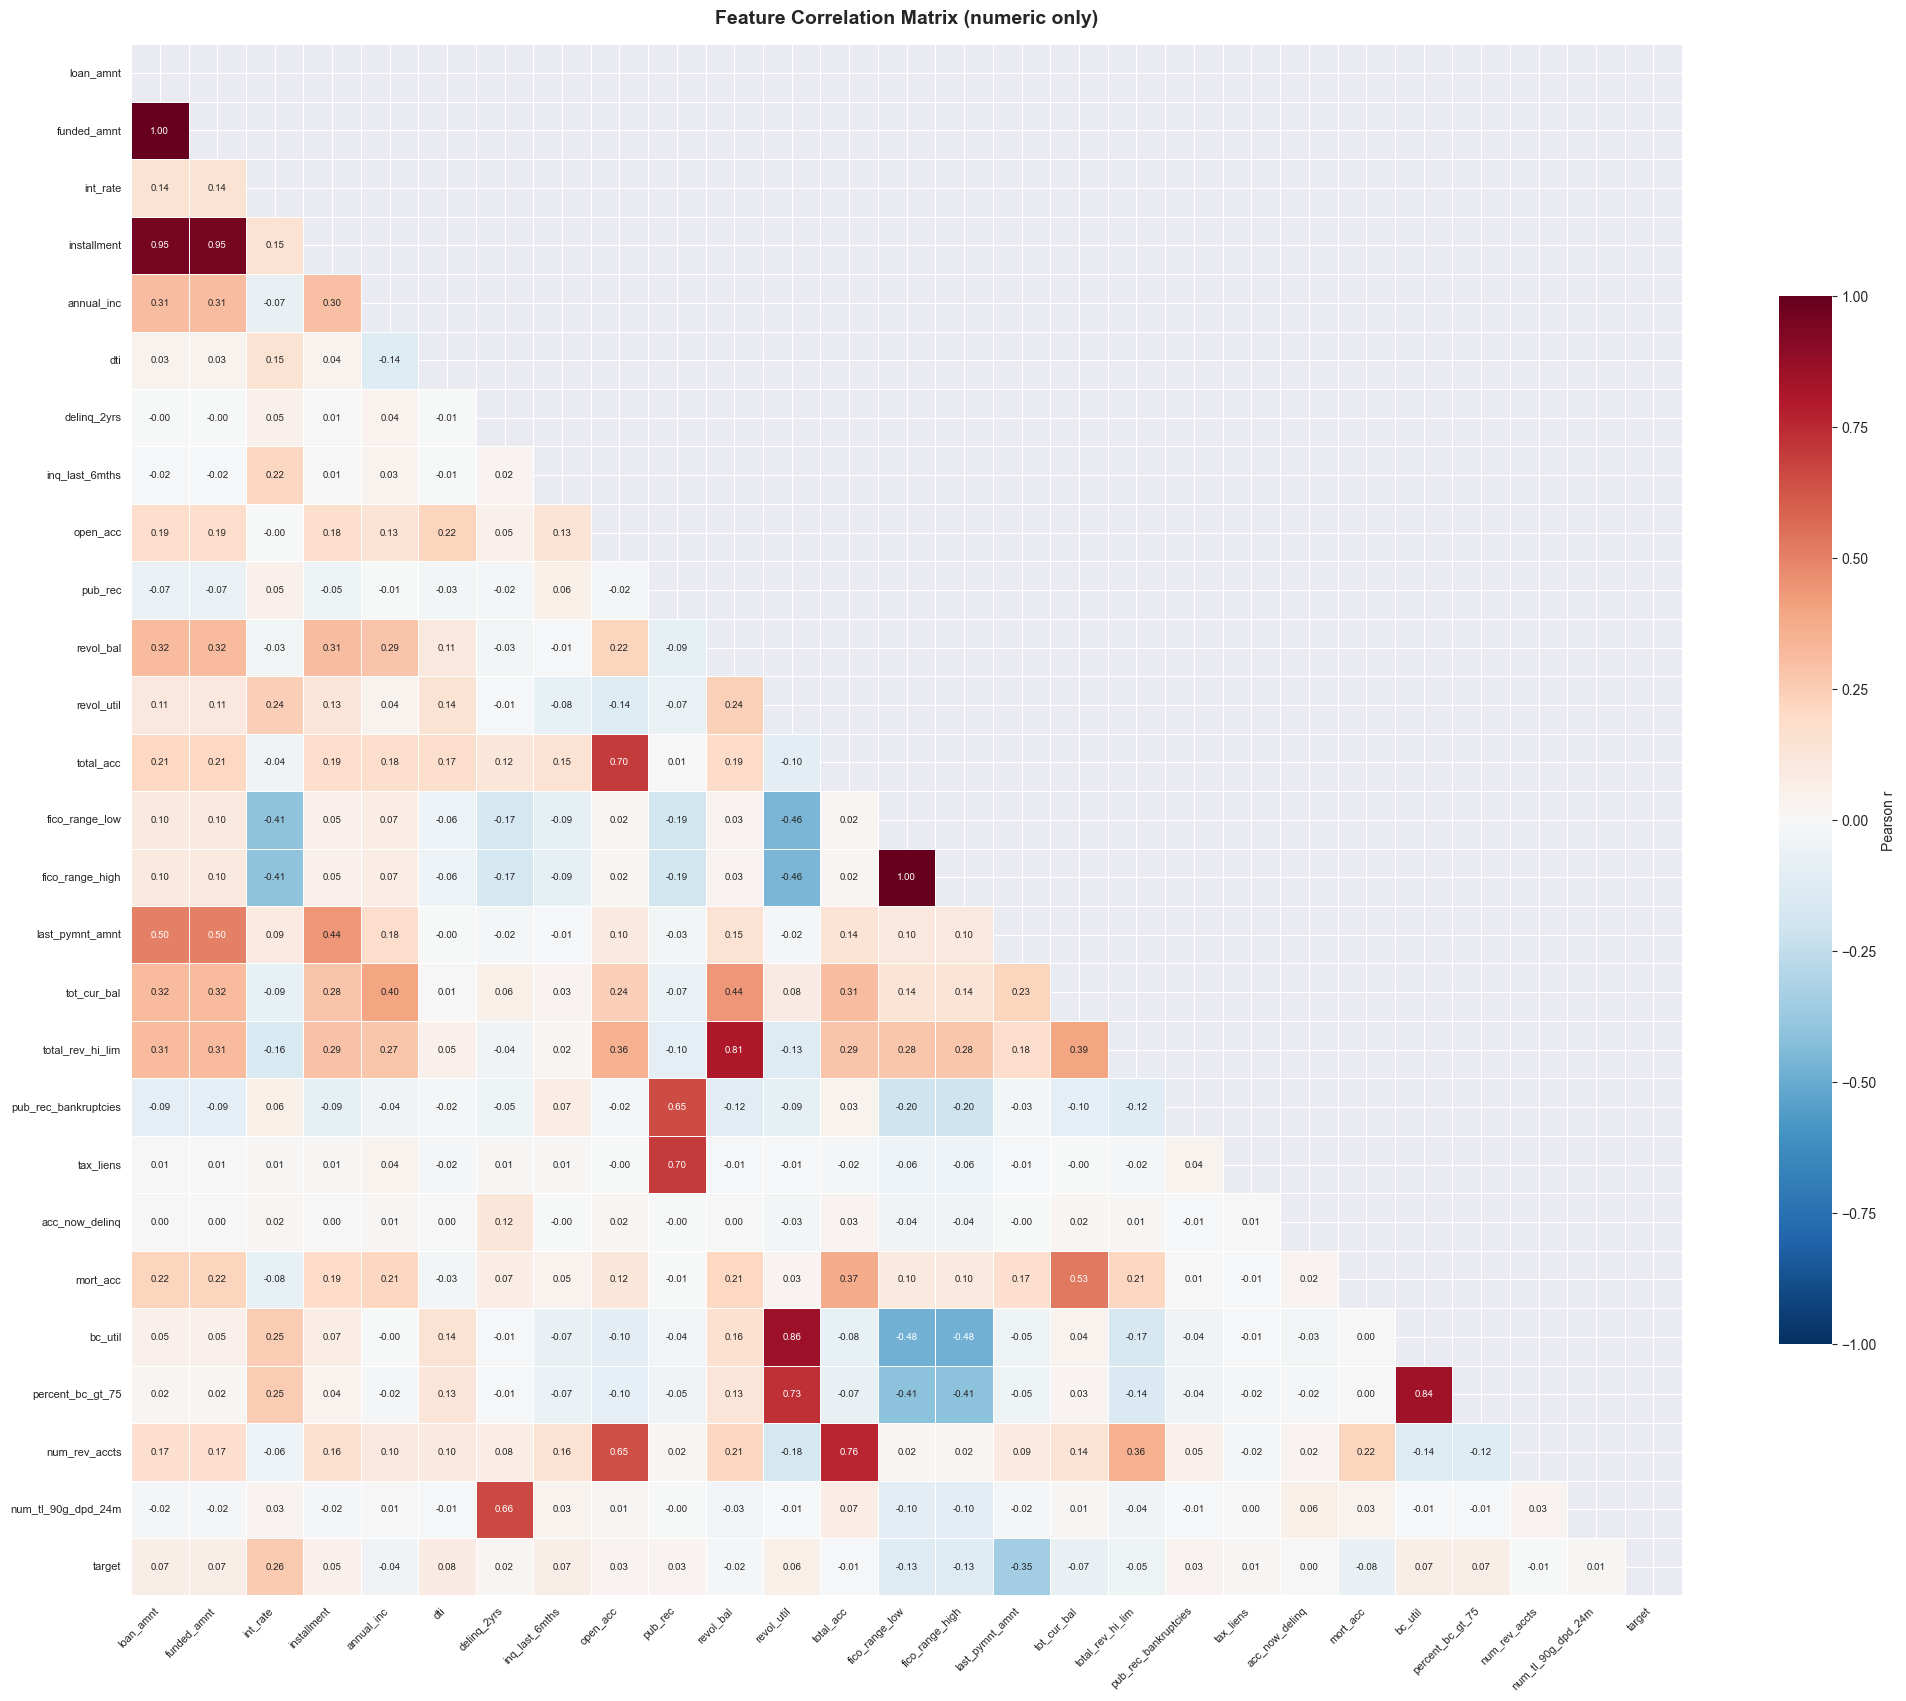


  Top 10 most correlated pairs:
     feature_1        feature_2  correlation
fico_range_low  fico_range_high     1.000000
     loan_amnt      funded_amnt     0.999562
   funded_amnt      installment     0.954053
     loan_amnt      installment     0.953401
    revol_util          bc_util     0.855022
       bc_util percent_bc_gt_75     0.844702
     revol_bal total_rev_hi_lim     0.810244
     total_acc    num_rev_accts     0.762554
    revol_util percent_bc_gt_75     0.726870
      open_acc        total_acc     0.701325


In [20]:
FEATURES = [
    # Loan info
    'loan_amnt', 'funded_amnt', 'term', 'int_rate', 'installment',
    'grade', 'sub_grade', 'purpose',
    # Borrower financials
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'pub_rec', 'revol_bal', 'revol_util', 'total_acc',
    # Employment
    'emp_length', 'home_ownership',
    # Credit history
    'earliest_cr_line', 'fico_range_low', 'fico_range_high',
    'last_pymnt_amnt', 'tot_cur_bal', 'total_rev_hi_lim',
    # Risk
    'verification_status', 'pub_rec_bankruptcies', 'tax_liens',
    'acc_now_delinq', 'mort_acc', 'bc_util', 'percent_bc_gt_75',
    'num_rev_accts', 'num_tl_90g_dpd_24m',
    # Target
    'target'
]

# Filter to only existing columns (safety check)
available = [col for col in FEATURES if col in accepted_df.columns]
df = accepted_df.select(available)
print(f"Selected {len(available) - 1} features + target")
print(f"   Shape: {df.shape}")

# Columns not in dataset
missing_cols = [col for col in FEATURES if col not in accepted_df.columns]
if missing_cols:
    print(f" Warning — not found in df: {missing_cols}")

# Feature correlation
feat_corr(df, FEATURES)

### Final features selection

In [21]:
FEATURES_FINAL = [
    "loan_to_income",
    "installment_to_monthly_income",
    "active_accounts_ratio",
    "inquiries_per_account",
    "installment_to_loan",
    "payment_to_loan",
    "interest_to_principal",
    # Loan info
    'loan_amnt', 'term', 'int_rate',
    'grade', 'sub_grade', 'purpose',
    # Borrower financials
    'annual_inc', 'dti', 'delinq_2yrs', 'inq_last_6mths',
    'open_acc', 'pub_rec', 'revol_bal', 'revol_util',
    # Employment
    'emp_length', 'home_ownership',
    # Credit history
    'earliest_cr_line', 'fico_range_low',
    'last_pymnt_amnt', 'tot_cur_bal',
    # Risk
    'verification_status', 'pub_rec_bankruptcies', 'tax_liens',
    'acc_now_delinq', 'mort_acc', 'bc_util', 'percent_bc_gt_75',
    'num_rev_accts', 'num_tl_90g_dpd_24m',
    # Target
    'target', "revolbal_to_income",
    "balance_to_credit_limit",
    "revolbal_per_account",
    "delinq_per_account",
    "pubrec_per_account"]





In [22]:
clean_df = accepted_df.select(FEATURES_FINAL)
print(clean_df.schema)           # dtypes
print(clean_df.shape)            # (rows, cols)
print(clean_df.null_count())

#  Separate features and target
X = clean_df.drop("target")
y = clean_df.select("target")
print(f"Final feature matrix : {X.shape}")
print(f" Target shape   : {y.shape}")
print(f" Default rate   : {y['target'].mean()*100:.2f}%")

Schema([('loan_to_income', Float64), ('installment_to_monthly_income', Float64), ('active_accounts_ratio', Float64), ('inquiries_per_account', Float64), ('installment_to_loan', Float64), ('payment_to_loan', Float64), ('interest_to_principal', Float64), ('loan_amnt', Float64), ('term', String), ('int_rate', Float64), ('grade', String), ('sub_grade', String), ('purpose', String), ('annual_inc', Float64), ('dti', Float64), ('delinq_2yrs', Float64), ('inq_last_6mths', Float64), ('open_acc', Float64), ('pub_rec', Float64), ('revol_bal', Float64), ('revol_util', Float64), ('emp_length', String), ('home_ownership', String), ('earliest_cr_line', String), ('fico_range_low', Float64), ('last_pymnt_amnt', Float64), ('tot_cur_bal', Float64), ('verification_status', String), ('pub_rec_bankruptcies', Float64), ('tax_liens', Float64), ('acc_now_delinq', Float64), ('mort_acc', Float64), ('bc_util', Float64), ('percent_bc_gt_75', Float64), ('num_rev_accts', Float64), ('num_tl_90g_dpd_24m', Float64), ('

### emp_length
emp_length: Employment length in years. Possible values are between 0 and 10 where 0 means less than one year and 10 means ten or more years.
$\rightarrow$ Replace $(<1, 0)$, $(10+, 10)$, and remove null rows

In [23]:
print(clean_df["emp_length"].value_counts().sort("count", descending=True))

shape: (12, 2)
┌────────────┬────────┐
│ emp_length ┆ count  │
│ ---        ┆ ---    │
│ str        ┆ u32    │
╞════════════╪════════╡
│ 10+ years  ┆ 442199 │
│ 2 years    ┆ 121743 │
│ < 1 year   ┆ 108061 │
│ 3 years    ┆ 107597 │
│ 1 year     ┆ 88494  │
│ 5 years    ┆ 84154  │
│ 4 years    ┆ 80556  │
│ null       ┆ 78511  │
│ 6 years    ┆ 62733  │
│ 8 years    ┆ 60701  │
│ 7 years    ┆ 59624  │
│ 9 years    ┆ 50937  │
└────────────┴────────┘


In [24]:
# transform emp_lenth columns
clean_df = clean_df.with_columns(
    pl.col("emp_length")
    .str.replace("10\\+ years", "10 years")
    .str.replace("< 1 year", "0 years")
    .str.extract(r"(\d+)")
    .cast(pl.Int8)
    .alias("emp_length")
)

# remove null values
clean_df = clean_df.drop_nulls(subset=["emp_length"])

print(clean_df["emp_length"].value_counts().sort("emp_length"))

shape: (11, 2)
┌────────────┬────────┐
│ emp_length ┆ count  │
│ ---        ┆ ---    │
│ i8         ┆ u32    │
╞════════════╪════════╡
│ 0          ┆ 108061 │
│ 1          ┆ 88494  │
│ 2          ┆ 121743 │
│ 3          ┆ 107597 │
│ 4          ┆ 80556  │
│ 5          ┆ 84154  │
│ 6          ┆ 62733  │
│ 7          ┆ 59624  │
│ 8          ┆ 60701  │
│ 9          ┆ 50937  │
│ 10         ┆ 442199 │
└────────────┴────────┘


### home_ownership
home_ownership: The home ownership status provided by the borrower.

Values: RENT, OWN, MORTGAGE, OTHER

In [25]:
# drop nulls and replace none/any to other
clean_df = (clean_df.drop_nulls(subset=["home_ownership"])
                  .with_columns(pl.col("home_ownership").replace({"NONE": "OTHER", "ANY": "OTHER"})))

print(clean_df["home_ownership"].value_counts().sort("count", descending=True))

shape: (4, 2)
┌────────────────┬────────┐
│ home_ownership ┆ count  │
│ ---            ┆ ---    │
│ str            ┆ u32    │
╞════════════════╪════════╡
│ MORTGAGE       ┆ 629291 │
│ RENT           ┆ 507862 │
│ OWN            ┆ 129192 │
│ OTHER          ┆ 454    │
└────────────────┴────────┘


### verification_status

verification_status: Indicates if income was verified by LendingClub.

Values: Verified, Source Verified, Not Verified

In [26]:
clean_df = clean_df.drop_nulls(subset=["verification_status"])
print(clean_df["verification_status"].value_counts().sort("count", descending=True))

shape: (3, 2)
┌─────────────────────┬────────┐
│ verification_status ┆ count  │
│ ---                 ┆ ---    │
│ str                 ┆ u32    │
╞═════════════════════╪════════╡
│ Source Verified     ┆ 506114 │
│ Not Verified        ┆ 389913 │
│ Verified            ┆ 370772 │
└─────────────────────┴────────┘


### pub_rec_bankcruptcies

In [27]:
clean_df = clean_df.drop_nulls(subset=["pub_rec_bankruptcies"])

print(clean_df["pub_rec_bankruptcies"].value_counts().sort("count", descending=True))

bktc_default = (
    clean_df
    .group_by("pub_rec_bankruptcies")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

shape: (12, 2)
┌──────────────────────┬─────────┐
│ pub_rec_bankruptcies ┆ count   │
│ ---                  ┆ ---     │
│ f64                  ┆ u32     │
╞══════════════════════╪═════════╡
│ 0.0                  ┆ 1114316 │
│ 1.0                  ┆ 142623  │
│ 2.0                  ┆ 7139    │
│ 3.0                  ┆ 1461    │
│ 4.0                  ┆ 361     │
│ 5.0                  ┆ 133     │
│ 6.0                  ┆ 42      │
│ 7.0                  ┆ 14      │
│ 8.0                  ┆ 8       │
│ 9.0                  ┆ 3       │
│ 12.0                 ┆ 1       │
│ 11.0                 ┆ 1       │
└──────────────────────┴─────────┘


### purpose
purpose: A category provided by the borrower for the loan request.

Values: debt_consolidation, credit_card, home_improvement, etc.

In [28]:
clean_df = clean_df.drop_nulls(subset=["purpose"])

print(clean_df["purpose"].value_counts().sort("count", descending=True))

purpose_default = (
    clean_df
    .group_by("purpose")
    .agg([
        pl.col("target").sum().alias("charged_off"),
        pl.len().alias("total")
    ])
    .with_columns(
        (pl.col("charged_off") / pl.col("total") * 100).alias("chargeoff_rate")
    )
    .sort("chargeoff_rate", descending=True)
    .to_pandas()
)

shape: (14, 2)
┌────────────────────┬────────┐
│ purpose            ┆ count  │
│ ---                ┆ ---    │
│ str                ┆ u32    │
╞════════════════════╪════════╡
│ debt_consolidation ┆ 737280 │
│ credit_card        ┆ 277310 │
│ home_improvement   ┆ 81205  │
│ other              ┆ 72144  │
│ major_purchase     ┆ 27754  │
│ small_business     ┆ 14924  │
│ medical            ┆ 14244  │
│ car                ┆ 13763  │
│ moving             ┆ 8875   │
│ vacation           ┆ 8366   │
│ house              ┆ 6818   │
│ wedding            ┆ 2243   │
│ renewable_energy   ┆ 876    │
│ educational        ┆ 300    │
└────────────────────┴────────┘


### annual_inc

annual_inc: The self-reported annual income provided by the borrower.

In [29]:
clean_df = clean_df.drop_nulls(subset=["annual_inc"])

print(clean_df["annual_inc"].describe())

# Bin into brackets
clean_df = clean_df.with_columns(
    pl.when(pl.col("annual_inc") < 30000).then(pl.lit("< 30k"))
    .when(pl.col("annual_inc") < 60000).then(pl.lit("30k–60k"))
    .when(pl.col("annual_inc") < 90000).then(pl.lit("60k–90k"))
    .when(pl.col("annual_inc") < 120000).then(pl.lit("90k–120k"))
    .otherwise(pl.lit("120k+"))
    .alias("income_bracket")
)

shape: (9, 2)
┌────────────┬──────────────┐
│ statistic  ┆ value        │
│ ---        ┆ ---          │
│ str        ┆ f64          │
╞════════════╪══════════════╡
│ count      ┆ 1.266102e6   │
│ null_count ┆ 0.0          │
│ mean       ┆ 77904.067011 │
│ std        ┆ 71068.992023 │
│ min        ┆ 0.0          │
│ 25%        ┆ 48000.0      │
│ 50%        ┆ 65000.0      │
│ 75%        ┆ 92555.0      │
│ max        ┆ 1.09992e7    │
└────────────┴──────────────┘


In [30]:
null_summary = (
    clean_df
    .null_count()
    .transpose(
        include_header=True,
        header_name="column",
        column_names=["null_count"]
    )
    .with_columns(
        (
            pl.col("null_count")
            / accepted_df.height
            * 100
        ).alias("null_pct")
    )
    .sort("null_pct", descending=True)
)

print(null_summary)

shape: (43, 3)
┌─────────────────────────┬────────────┬──────────┐
│ column                  ┆ null_count ┆ null_pct │
│ ---                     ┆ ---        ┆ ---      │
│ str                     ┆ u32        ┆ f64      │
╞═════════════════════════╪════════════╪══════════╡
│ num_rev_accts           ┆ 64804      ┆ 4.817031 │
│ tot_cur_bal             ┆ 64803      ┆ 4.816957 │
│ num_tl_90g_dpd_24m      ┆ 64803      ┆ 4.816957 │
│ balance_to_credit_limit ┆ 64803      ┆ 4.816957 │
│ bc_util                 ┆ 58594      ┆ 4.355427 │
│ percent_bc_gt_75        ┆ 58228      ┆ 4.328222 │
│ mort_acc                ┆ 45244      ┆ 3.363091 │
│ revol_util              ┆ 806        ┆ 0.059912 │
│ dti                     ┆ 17         ┆ 0.001264 │
│ inquiries_per_account   ┆ 1          ┆ 0.000074 │
│ …                       ┆ …          ┆ …        │
│ verification_status     ┆ 0          ┆ 0.0      │
│ pub_rec_bankruptcies    ┆ 0          ┆ 0.0      │
│ tax_liens               ┆ 0          ┆ 0.0     

In [31]:
count_cols = [
    "num_rev_accts",
    "num_tl_90g_dpd_24m",
    "mort_acc"
]

clean_df = clean_df.with_columns([
    pl.col(c).fill_null(0)
    for c in count_cols
])

In [32]:
median_cols = [
    "tot_cur_bal",
    "bc_util",
    "percent_bc_gt_75",
    "revol_util",
    "dti"
]

clean_df = clean_df.with_columns([
    pl.col(c).fill_null(
        accepted_df.select(pl.col(c).median()).item()
    )
    for c in median_cols
])

In [33]:
clean_df = clean_df.with_columns([
    pl.col("inq_last_6mths").fill_null(0),
    pl.col("inquiries_per_account").fill_null(0)
])

In [34]:
# 1. emp_length -> mode
clean_df = clean_df.with_columns(
    pl.col("emp_length").fill_null(
        clean_df.select(
            pl.col("emp_length").mode().first()
        ).item()
    )
)

# 2. Count variables -> 0
count_cols = [
    "num_rev_accts",
    "num_tl_90g_dpd_24m",
    "mort_acc",
    "pub_rec_bankruptcies"
]

clean_df = clean_df.with_columns([
    pl.col(col).fill_null(0)
    for col in count_cols
])

# 3. Continuous variables -> median
median_cols = [
    "tot_cur_bal",
    "bc_util",
    "percent_bc_gt_75",
    "revol_util"
]

clean_df = clean_df.with_columns([
    pl.col(col).fill_null(
        clean_df.select(
            pl.col(col).median()
        ).item()
    )
    for col in median_cols
])


In [35]:
null_summary = (
    clean_df
    .null_count()
    .transpose(
        include_header=True,
        header_name="column",
        column_names=["null_count"]
    )
    .with_columns(
        (
            pl.col("null_count")
            / clean_df.height
            * 100
        ).alias("null_pct")
    )
    .filter(pl.col("null_count") > 0)
    .sort("null_pct", descending=True)
)

print(null_summary)

shape: (1, 3)
┌─────────────────────────┬────────────┬──────────┐
│ column                  ┆ null_count ┆ null_pct │
│ ---                     ┆ ---        ┆ ---      │
│ str                     ┆ u32        ┆ f64      │
╞═════════════════════════╪════════════╪══════════╡
│ balance_to_credit_limit ┆ 64803      ┆ 5.118308 │
└─────────────────────────┴────────────┴──────────┘


In [36]:

# Median fills
for col in ["balance_to_credit_limit", "dti"]:
    median_val = clean_df.select(
        pl.col(col).median()
    ).item()

    clean_df = clean_df.with_columns(
        pl.col(col).fill_null(median_val)
    )

# Count/event variables -> 0
clean_df = clean_df.with_columns([
    pl.col("tax_liens").fill_null(0),
    pl.col("inquiries_per_account").fill_null(0),
    pl.col("inq_last_6mths").fill_null(0)
])

In [37]:
null_summary = (
    clean_df
    .null_count()
    .transpose(
        include_header=True,
        header_name="column",
        column_names=["null_count"]
    )
    .filter(pl.col("null_count") > 0)
)

print(null_summary)

shape: (0, 2)
┌────────┬────────────┐
│ column ┆ null_count │
│ ---    ┆ ---        │
│ str    ┆ u32        │
╞════════╪════════════╡
└────────┴────────────┘


In [38]:
remaining_nulls = (
    clean_df
    .null_count()
    .select(pl.sum_horizontal(pl.all()))
    .item()
)

print("Remaining nulls:", remaining_nulls)

Remaining nulls: 0


In [39]:
null_summary = (
    clean_df
    .null_count()
    .transpose(
        include_header=True,
        header_name="column",
        column_names=["null_count"]
    )
    .with_columns(
        (
            pl.col("null_count")
            / accepted_df.height
            * 100
        ).alias("null_pct")
    )
    .sort("null_pct", descending=True)
)

print(null_summary)

shape: (43, 3)
┌───────────────────────────────┬────────────┬──────────┐
│ column                        ┆ null_count ┆ null_pct │
│ ---                           ┆ ---        ┆ ---      │
│ str                           ┆ u32        ┆ f64      │
╞═══════════════════════════════╪════════════╪══════════╡
│ loan_to_income                ┆ 0          ┆ 0.0      │
│ installment_to_monthly_income ┆ 0          ┆ 0.0      │
│ active_accounts_ratio         ┆ 0          ┆ 0.0      │
│ inquiries_per_account         ┆ 0          ┆ 0.0      │
│ installment_to_loan           ┆ 0          ┆ 0.0      │
│ payment_to_loan               ┆ 0          ┆ 0.0      │
│ interest_to_principal         ┆ 0          ┆ 0.0      │
│ loan_amnt                     ┆ 0          ┆ 0.0      │
│ term                          ┆ 0          ┆ 0.0      │
│ int_rate                      ┆ 0          ┆ 0.0      │
│ …                             ┆ …          ┆ …        │
│ percent_bc_gt_75              ┆ 0          ┆ 0.0      │

## Save cleaned file

In [40]:
clean_df.write_parquet("data/processed_data/processed_accepted_df.parquet")